# HMC-NNN Datalab — Basis-EDA: zorgplannen en opnameduur

**Minor Data & Health Innovation · HMC-NNN**

Dit notebook is het **gedeelde startpunt** voor iedereen in de groep. We onderzoeken of
gestandaardiseerde verpleegkundige zorgplandata — **NANDA-I** diagnoses en **NOC**
uitkomstindicatoren — samen met de medische opname-indicatie (**ICD-10**) iets zeggen over
de **opnameduur** (*Length of Stay*, LOS) van een patiënt.

## Hoe gebruik je dit notebook?

1. Installeer eenmalig de pakketten: `pip install -r requirements.txt`
2. Open dit notebook — vanuit de project-root **of** vanuit de map `notebooks/`, beide werken.
3. Kies *Run All*. Alle cellen draaien van boven naar beneden.

Alle inlees- en rekenlogica staat in **`src/data_loader.py`**. Dat is bewust: maak je straks
je eigen notebook voor feature engineering of modellering, importeer dan dezelfde functies
in plaats van code te kopiëren. Zo rekent iedereen in de groep met **dezelfde definitie van
opnameduur**.

## De data in het kort

De export staat op **meting-niveau**: één rij = één NOC-indicator, op één meetmoment
(`Baseline` of `Eindscore`), binnen één NANDA-diagnose, binnen één opname (`Opnamenummer`).
Daaruit leiden we twee analysetabellen af:

| Tabel | Eén rij per | Belangrijkste kolommen |
|---|---|---|
| `df` | meting | opgeschoonde meetrijen + afgeleide opnamegrenzen |
| `df_diagnoses` | (`Opnamenummer`, `Diagnose`) | `Diagnoseduur_dagen`, `Compleetheid`, `Start_dag_offset` |
| `df_opnames` | `Opnamenummer` (= het zorgplan) | `Opnameduur_dagen`, `n_diagnoses_totaal`, `n_indicatoren_totaal` |

### Hoe meten we opnameduur?

In de export zit **geen** administratieve opname- en ontslagdatum. We benaderen de
opnameduur daarom met de meetdatums binnen hetzelfde `Opnamenummer`:

- `Opnameduur_dagen = max(Meetdatum) − min(Meetdatum)` over **alle** metingen van de opname.
- `Diagnoseduur_dagen = max(Eindscore-datum) − min(Baseline-datum)` per NANDA-diagnose.

Dat is een **ondergrens**: de echte opname begint mogelijk eerder dan de eerste meting en
eindigt later dan de laatste. Houd dat in je achterhoofd bij elke conclusie hieronder.

> **Let op — dit is een testset.** De huidige export bevat slechts **10 opnames**. Alle
> correlaties en p-waarden hieronder zijn dus *indicatief*: ze laten zien **hoe** je de
> analyse doet, niet **wat** er waar is. De code schaalt één op één naar de volledige
> HMC-dataset (~25.000 opnames).

## Inhoud

1. [Pijler 1 — Datakwaliteit & zorgplan-integriteit](#pijler1)
2. [Pijler 2 — Opnameduur versus individuele diagnoseduur](#pijler2)
3. [Pijler 3 — Zorgplan-complexiteit versus opnameduur](#pijler3)
4. [Pijler 4 — Startmoment van diagnoses & data leakage](#pijler4)
5. [Pijler 5 — ICD-10 versus NANDA/NOC](#pijler5)
6. [Aanbevelingen voor feature engineering & modellering](#aanbevelingen)

## 0. Setup

### 0.1 Imports en project-root

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator
from scipy import stats


def vind_project_root() -> Path:
    """Zoekt omhoog vanaf de huidige map tot src/data_loader.py gevonden is.

    Hierdoor werkt dit notebook zowel vanuit de project-root als vanuit notebooks/.
    """
    for kandidaat in [Path.cwd(), *Path.cwd().parents]:
        if (kandidaat / "src" / "data_loader.py").is_file():
            return kandidaat
    raise FileNotFoundError(
        "Kan de project-root niet vinden: src/data_loader.py ontbreekt in deze map "
        "en in alle bovenliggende mappen."
    )


PROJECT_ROOT = vind_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    build_admission_table,
    build_diagnosis_table,
    load_and_clean_hmc_data,
)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

print("Project-root:", PROJECT_ROOT)

Project-root: C:\Users\qsoerohardjo\Documents\hmc-nnn


### 0.2 Huisstijl voor de grafieken

We zetten één keer een rustige, consistente stijl op: dunne marks, hairline gridlijnen,
geen kader. Gebruik `BLAUW` voor "de serie" en `NEUTRAAL` voor "de rest" wanneer je één
ding wilt uitlichten. Zo zien alle grafieken in de groep er hetzelfde uit.

In [2]:
# Oppervlak en inkt
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECUNDAIR = "#52514e"
GRID = "#e1e0d9"
AS = "#c3c2b7"

# Vaste categorische volgorde - niet doorrollen voorbij slot 8
PALET = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
         "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLAUW, ORANJE, AQUA = PALET[0], PALET[1], PALET[2]
NEUTRAAL = "#c9c8c1"   # 'de rest' in nadruk-grafieken

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "figure.dpi": 110,
    "savefig.facecolor": SURFACE,
    "savefig.bbox": "tight",
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AS,
    "axes.linewidth": 0.8,
    "axes.labelcolor": INK_SECUNDAIR,
    "axes.titlecolor": INK,
    "axes.titlesize": 11.5,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "grid.linestyle": "-",
    "xtick.color": AS,
    "ytick.color": AS,
    "xtick.labelcolor": INK_SECUNDAIR,
    "ytick.labelcolor": INK_SECUNDAIR,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10,
    "lines.linewidth": 2,
    "lines.markersize": 8,
    "legend.frameon": False,
    "legend.fontsize": 9,
})


def stijl_as(ax, waarde_as="y"):
    """Hairline grid op alleen de waarde-as; de categorie-as blijft schoon."""
    ax.grid(axis=waarde_as, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    return ax


def hele_dagen(ax, as_naam="x"):
    """Dagen en aantallen zijn hele getallen; voorkom tickets als '2.5 dagen'."""
    as_object = ax.xaxis if as_naam == "x" else ax.yaxis
    as_object.set_major_locator(MaxNLocator(integer=True))
    return ax


def label_balken(ax, balken, waarden, horizontaal=False, suffix="", overslaan=()):
    """Zet de waarde als tekst aan het uiteinde van elke balk.

    Bij gestapelde balken telt get_x() mee, zodat het label achter de stapel staat
    en niet op de breedte van het laatste segment.
    """
    for index, (rect, waarde) in enumerate(zip(balken, waarden)):
        if index in overslaan:
            continue
        if horizontaal:
            ax.text(rect.get_x() + rect.get_width(), rect.get_y() + rect.get_height() / 2,
                    f"  {waarde}{suffix}", va="center", ha="left",
                    color=INK_SECUNDAIR, fontsize=9)
        else:
            ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height(),
                    f"{waarde}{suffix}", va="bottom", ha="center",
                    color=INK_SECUNDAIR, fontsize=9)

### 0.3 Data inladen en valideren

`load_and_clean_hmc_data()` zoekt zelf naar `Test datasheet NNN Minor.xlsx`, hernoemt de
DAX-achtige kolomnaam `'RAPm vNandaNicNoc_Probleem'[Opnamenummer]` naar `Opnamenummer`,
zet Excel-datums om naar echte `datetime`-objecten en controleert of alle 12 kernkolommen
aanwezig zijn. Ontbreekt er één, dan krijg je een foutmelding die precies zegt welke.

In [3]:
df = load_and_clean_hmc_data()
df_diagnoses = build_diagnosis_table(df)
df_opnames = build_admission_table(df, df_diagnoses)

print(f"Metingen (rijen)        : {len(df)}")
print(f"Unieke patienten        : {df['Patientnr'].nunique()}")
print(f"Unieke opnames          : {df['Opnamenummer'].nunique()}")
print(f"Unieke NANDA-diagnoses  : {df['Diagnose'].nunique()}")
print(f"Unieke NOC-indicatoren  : {df['Indicator'].nunique()}")
print(f"Meetperiode             : {df['Meetdatum'].min():%d-%m-%Y} t/m {df['Meetdatum'].max():%d-%m-%Y}")
print()
print(f"df_diagnoses : {df_diagnoses.shape[0]} rijen x {df_diagnoses.shape[1]} kolommen")
print(f"df_opnames   : {df_opnames.shape[0]} rijen x {df_opnames.shape[1]} kolommen")

Metingen (rijen)        : 226
Unieke patienten        : 10
Unieke opnames          : 10
Unieke NANDA-diagnoses  : 13
Unieke NOC-indicatoren  : 58
Meetperiode             : 02-07-2026 t/m 29-09-2026

df_diagnoses : 37 rijen x 23 kolommen
df_opnames   : 10 rijen x 20 kolommen


In [4]:
# Harde controle op de datatypes waar de rest van het notebook op leunt.
assert pd.api.types.is_datetime64_any_dtype(df["Meetdatum"]), "Meetdatum is geen datetime"
assert pd.api.types.is_datetime64_any_dtype(df["Meet_datetime"]), "Meet_datetime is geen datetime"
assert str(df["MeetScore"].dtype) == "Int64", "MeetScore is niet numeriek"
assert df["Opnamenummer"].notna().all(), "Er zijn metingen zonder Opnamenummer"

df.dtypes.to_frame("dtype")

,dtype
Patientnr,Int64
Opnamenummer,Int64
Diagnose,object
Indicator,object
MeetScore,Int64
Score_omschrijving,object
Gezondheidswinst,float64
Meetdatum,datetime64[ns]
Meettijd,object
Meetmoment,object


In [5]:
df.head(8)

,Patientnr,Opnamenummer,Diagnose,Indicator,MeetScore,Score_omschrijving,Gezondheidswinst,Meetdatum,Meettijd,Meetmoment,ICD10Code,ICD10Omschrijving,Meet_datetime,Opname_startdatum,Opname_einddatum,Opnameduur_dagen,Meet_dag_van_opname
0,1,1,Acute pijn,Melding van pijn,3,Matig,NaN,2026-09-18,00:00,Baseline,S72.00,Fractuur van femurhals; gesloten,2026-09-18 00:00:00,2026-09-18,2026-09-25,7,0
1,1,1,Acute pijn,Melding van pijn,4,Enigszins,1.0,2026-09-25,07:00,Eindscore,S72.00,Fractuur van femurhals; gesloten,2026-09-25 07:00:00,2026-09-18,2026-09-25,7,7
2,1,1,"Mobiliteitstekort, lichamelijk",Gemak waarmee algemene dagelij,3,Matig beperkt,NaN,2026-09-20,15:00,Baseline,S72.00,Fractuur van femurhals; gesloten,2026-09-20 15:00:00,2026-09-18,2026-09-25,7,2
3,1,1,"Mobiliteitstekort, lichamelijk",Verplaatsingsvermogen,3,Matig beperkt,NaN,2026-09-20,15:00,Baseline,S72.00,Fractuur van femurhals; gesloten,2026-09-20 15:00:00,2026-09-18,2026-09-25,7,2
4,1,1,"Mobiliteitstekort, lichamelijk",Gemak waarmee algemene dagelij,4,Enigszins beperkt,1.0,2026-09-25,07:00,Eindscore,S72.00,Fractuur van femurhals; gesloten,2026-09-25 07:00:00,2026-09-18,2026-09-25,7,7
5,1,1,"Mobiliteitstekort, lichamelijk",Verplaatsingsvermogen,4,Enigszins beperkt,1.0,2026-09-25,07:00,Eindscore,S72.00,Fractuur van femurhals; gesloten,2026-09-25 07:00:00,2026-09-18,2026-09-25,7,7
6,1,1,Risico op vallen bij volwassenen,Bed staat in lage positie,5,Volledig adequaat,NaN,2026-09-19,00:00,Baseline,S72.00,Fractuur van femurhals; gesloten,2026-09-19 00:00:00,2026-09-18,2026-09-25,7,1
7,1,1,Risico op vallen bij volwassenen,Bed staat in lage positie,5,Volledig adequaat,0.0,2026-09-25,07:00,Eindscore,S72.00,Fractuur van femurhals; gesloten,2026-09-25 07:00:00,2026-09-18,2026-09-25,7,7


<a id="pijler1"></a>

---

## 1. Pijler 1 — Datakwaliteit & zorgplan-integriteit

Voordat we iets over opnameduur zeggen, moeten we weten **hoe betrouwbaar de registratie
is**. Drie vragen:

1. Welke velden zijn leeg, en is dat erg?
2. Hoe is `MeetScore` verdeeld — hoeveel metingen zeggen eigenlijk "geen probleem"?
3. Hoeveel diagnoses zijn **compleet** (Baseline én Eindscore) en hoeveel zijn
   **wees-metingen** (maar één van de twee)?

### 1.1 Ontbrekende waarden

In [6]:
ontbrekend = (
    df.isna().sum()
      .rename("Aantal_leeg")
      .to_frame()
      .assign(Percentage=lambda t: (t["Aantal_leeg"] / len(df) * 100).round(1))
      .loc[lambda t: t["Aantal_leeg"] > 0]
      .sort_values("Aantal_leeg", ascending=False)
)

n_baseline = int((df["Meetmoment"] == "Baseline").sum())
n_eindscore = int((df["Meetmoment"] == "Eindscore").sum())
leeg_bij_eind = int(df.loc[df["Meetmoment"] == "Eindscore", "Gezondheidswinst"].isna().sum())

print(f"Baseline-rijen : {n_baseline}")
print(f"Eindscore-rijen: {n_eindscore}")
print(f"Gezondheidswinst leeg bij een Eindscore-rij: {leeg_bij_eind}")
ontbrekend

Baseline-rijen : 109
Eindscore-rijen: 117
Gezondheidswinst leeg bij een Eindscore-rij: 10


,Aantal_leeg,Percentage
Gezondheidswinst,119,52.7


**Lezen:** `Gezondheidswinst` is per definitie leeg bij een `Baseline` — daar valt nog niets
te winnen. Alleen de lege waarden bij een **`Eindscore`** zijn echte registratiegaten. Alle
andere kernkolommen zijn volledig gevuld; dat is voor een ziekenhuisexport opvallend netjes
en iets om bij de volledige dataset opnieuw te controleren.

### 1.2 Verdeling van `MeetScore`

In NOC betekent score **5** meestal *"geen probleem / niet beperkt"*. Een zorgplan vol
vijven beschrijft dus niet per se een zware patiënt — het beschrijft een patiënt bij wie op
die indicator níéts aan de hand is. Dat onderscheid bepaalt straks welke
complexiteitsmaat zinvol is.

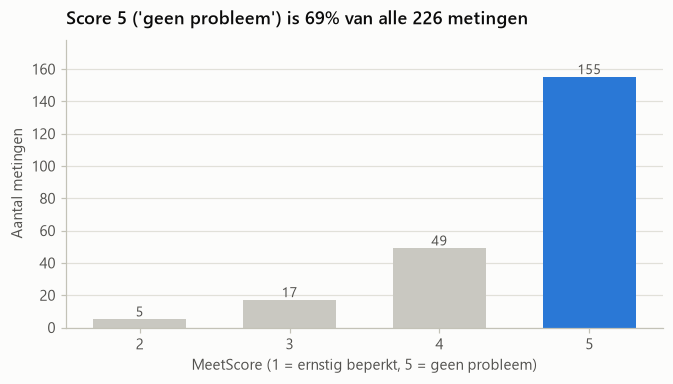

,Aantal,Voorbeeld_omschrijving
MeetScore,,
2,5,Ernstig beperkt
3,17,Matig
4,49,Enigszins
5,155,Volledig adequaat


In [7]:
score_verdeling = df["MeetScore"].value_counts().sort_index()
pct_vijf = float((df["MeetScore"] == 5).mean() * 100)

fig, ax = plt.subplots(figsize=(7, 3.4))
kleuren = [BLAUW if score == 5 else NEUTRAAL for score in score_verdeling.index]
balken = ax.bar(score_verdeling.index.astype(str), score_verdeling.to_numpy(),
                color=kleuren, width=0.62)
label_balken(ax, balken, score_verdeling.to_numpy())

ax.set_title(f"Score 5 ('geen probleem') is {pct_vijf:.0f}% van alle {len(df)} metingen")
ax.set_xlabel("MeetScore (1 = ernstig beperkt, 5 = geen probleem)")
ax.set_ylabel("Aantal metingen")
ax.set_ylim(0, score_verdeling.max() * 1.15)
stijl_as(ax, "y")
plt.show()

df.groupby("MeetScore", observed=True)["Score_omschrijving"].agg(
    Aantal="size", Voorbeeld_omschrijving=lambda s: s.dropna().iloc[0] if s.notna().any() else ""
)

### 1.3 Complete diagnoses versus wees-metingen

Een diagnose is **compleet** als er zowel een `Baseline` als een `Eindscore` is. Ontbreekt
er één, dan kun je voor die diagnose géén doorlooptijd berekenen — en weet je ook niet of de
diagnose is afgesloten of gewoon niet is afgerond in het dossier.

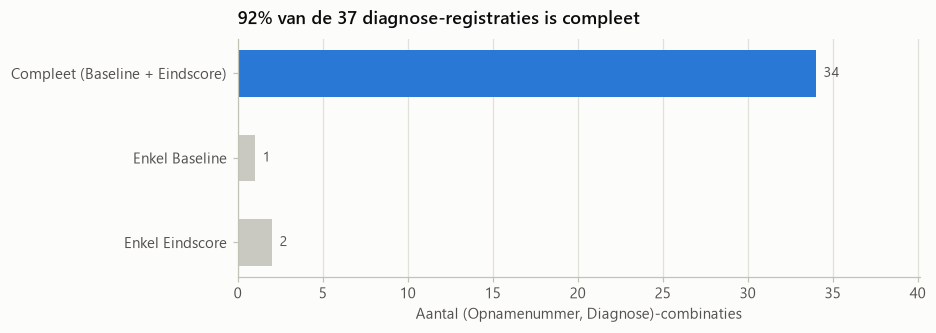

In [8]:
compleetheid = df_diagnoses["Compleetheid"].value_counts()
volgorde = [c for c in ["Compleet (Baseline + Eindscore)", "Enkel Baseline", "Enkel Eindscore", "Overig"]
            if c in compleetheid.index]
compleetheid = compleetheid.loc[volgorde]
pct_compleet = compleetheid.get("Compleet (Baseline + Eindscore)", 0) / compleetheid.sum() * 100

fig, ax = plt.subplots(figsize=(8, 2.8))
kleuren = [BLAUW if "Compleet" in naam else NEUTRAAL for naam in compleetheid.index]
balken = ax.barh(compleetheid.index[::-1], compleetheid.to_numpy()[::-1],
                 color=kleuren[::-1], height=0.55)
label_balken(ax, balken, compleetheid.to_numpy()[::-1], horizontaal=True)

ax.set_title(f"{pct_compleet:.0f}% van de {compleetheid.sum()} diagnose-registraties is compleet")
ax.set_xlabel("Aantal (Opnamenummer, Diagnose)-combinaties")
ax.set_xlim(0, compleetheid.max() * 1.18)
stijl_as(ax, "x")
plt.show()

In [9]:
# Welke diagnoses missen een Baseline of een Eindscore? Deze vallen straks uit de
# analyse van individuele diagnoseduur.
wees = df_diagnoses.loc[
    df_diagnoses["Compleetheid"] != "Compleet (Baseline + Eindscore)",
    ["Opnamenummer", "Patientnr", "Diagnose", "Compleetheid",
     "Aantal_indicatoren", "Diagnose_startdatum", "Diagnose_einddatum"],
].reset_index(drop=True)

print(f"{len(wees)} van de {len(df_diagnoses)} diagnoses zijn onvolledig geregistreerd.")
wees

3 van de 37 diagnoses zijn onvolledig geregistreerd.


,Opnamenummer,Patientnr,Diagnose,Compleetheid,Aantal_indicatoren,Diagnose_startdatum,Diagnose_einddatum
0,7,7,Angst,Enkel Baseline,2,2026-09-16,NaT
1,9,9,Risico op vallen bij volwassenen,Enkel Eindscore,5,NaT,2026-07-17
2,10,10,Weefseldefect,Enkel Eindscore,4,NaT,2026-09-01


In [10]:
# Herhaalde metingen: meer dan een Baseline- of Eindscore-datum binnen dezelfde diagnose.
herhaald = df_diagnoses.loc[
    (df_diagnoses["Aantal_baseline_datums"] > 1) | (df_diagnoses["Aantal_eindscore_datums"] > 1),
    ["Opnamenummer", "Diagnose", "Aantal_baseline_datums", "Aantal_eindscore_datums",
     "Aantal_meting_rijen"],
]
if herhaald.empty:
    print("Geen diagnoses met meerdere Baseline- of Eindscore-datums.")
else:
    display(herhaald.reset_index(drop=True))

,Opnamenummer,Diagnose,Aantal_baseline_datums,Aantal_eindscore_datums,Aantal_meting_rijen
0,1,Risico op vallen bij volwassenen,2,1,10
1,4,"Mobiliteitstekort, lichamelijk",1,2,6
2,8,Disfunctionele gastro-intestinale peristaltiek,2,1,12
3,8,Risico op acute verwardheid,2,1,18
4,8,Risico op vallen bij volwassenen,1,4,23


> **Conclusie pijler 1.** De registratie is grotendeels compleet, maar een handvol diagnoses
> mist een Baseline of een Eindscore. Voor **opnameduur** maakt dat niets uit — die rekenen we
> op `min`/`max` van *alle* meetdatums, ongeacht het label. Voor **diagnoseduur** wel: die
> rijen krijgen `NaN` en moeten bewust worden uitgesloten, niet stilzwijgend op 0 gezet.

<a id="pijler2"></a>

---

## 2. Pijler 2 — Opnameduur versus individuele diagnoseduur

Een zorgplan (`Opnamenummer`) is geen blok: het bestaat uit diagnoses die op verschillende
momenten starten en stoppen. Hier zetten we die twee tijdschalen naast elkaar.

### 2.1 Opnameduur per opname

Gemiddelde opnameduur : 6.6 dagen
Mediane opnameduur    : 6.5 dagen
Spreiding             : 0 t/m 13 dagen
Dagopnames (0 dagen)  : 1


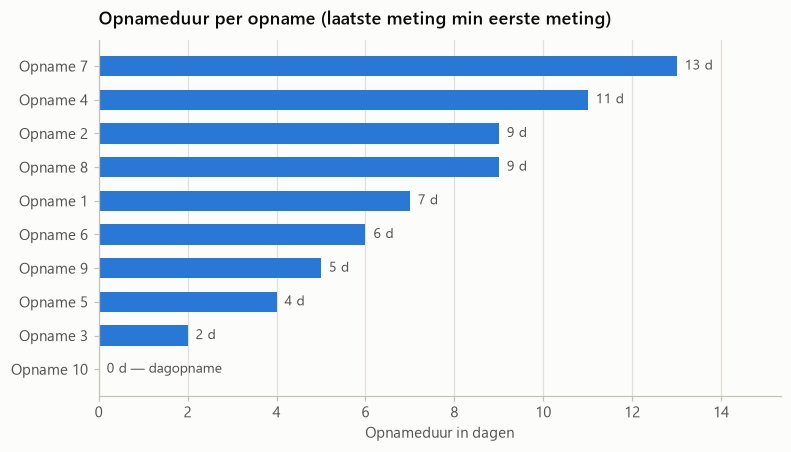

In [11]:
los = df_opnames["Opnameduur_dagen"]
print(f"Gemiddelde opnameduur : {los.mean():.1f} dagen")
print(f"Mediane opnameduur    : {los.median():.1f} dagen")
print(f"Spreiding             : {los.min()} t/m {los.max()} dagen")
print(f"Dagopnames (0 dagen)  : {int(df_opnames['Is_dagopname'].sum())}")

gesorteerd = df_opnames.sort_values("Opnameduur_dagen")
labels = [f"Opname {int(n)}" for n in gesorteerd["Opnamenummer"]]

dagopname_posities = [i for i, vlag in enumerate(gesorteerd["Is_dagopname"]) if vlag]

fig, ax = plt.subplots(figsize=(8, 4.2))
balken = ax.barh(labels, gesorteerd["Opnameduur_dagen"].to_numpy(), color=BLAUW, height=0.6)
label_balken(ax, balken, gesorteerd["Opnameduur_dagen"].to_numpy(),
             horizontaal=True, suffix=" d", overslaan=dagopname_posities)

# Een dagopname heeft balklengte 0 en is anders onzichtbaar: benoem die expliciet.
for i in dagopname_posities:
    rect = balken[i]
    ax.text(0, rect.get_y() + rect.get_height() / 2, "  0 d — dagopname",
            va="center", ha="left", color=INK_SECUNDAIR, fontsize=9)

ax.set_title("Opnameduur per opname (laatste meting min eerste meting)")
ax.set_xlabel("Opnameduur in dagen")
ax.set_xlim(0, los.max() * 1.18)
stijl_as(ax, "x")
hele_dagen(ax, "x")
plt.show()

De opname met 0 dagen is geen fout: alle metingen vielen op dezelfde kalenderdag. In de
volledige dataset wil je zulke dagopnames apart kunnen behandelen — vandaar de kolom
`Is_dagopname`.

### 2.2 Doorlooptijd per NANDA-diagnose

Hoe lang staat een diagnose open? Alleen complete diagnoses tellen mee; wees-metingen
hebben geen doorlooptijd.

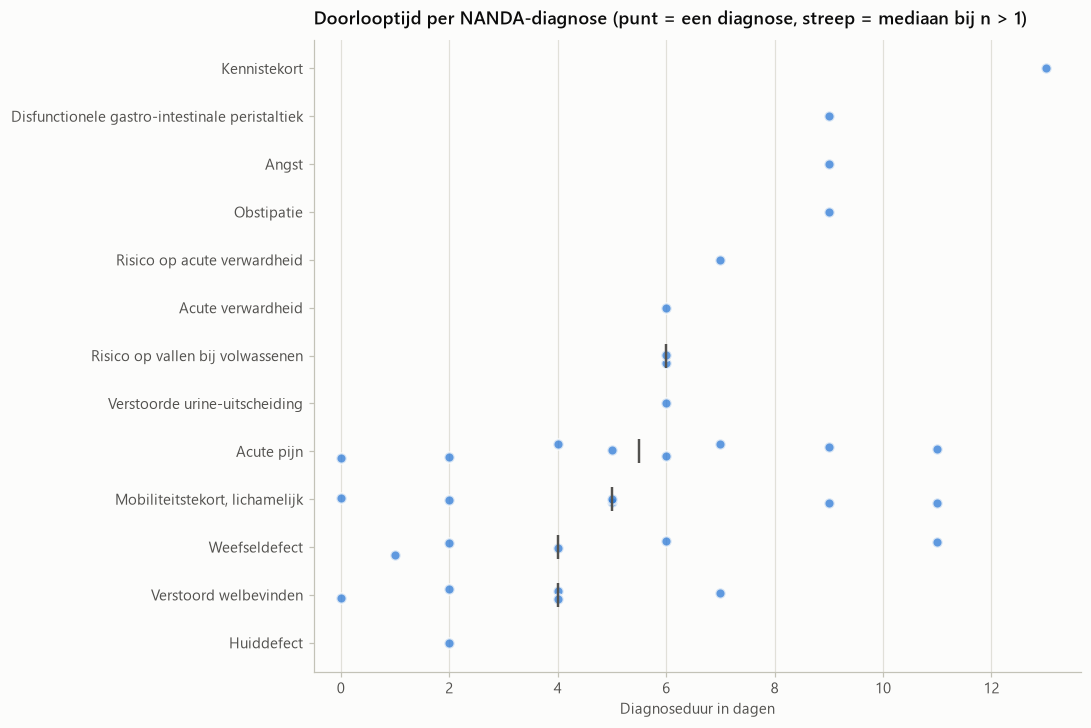

,Aantal,Mediaan,Gemiddeld,Min,Max
Diagnose,,,,,
Kennistekort,1,13.0,13.0,13.0,13.0
Disfunctionele gastro-intestinale peristaltiek,1,9.0,9.0,9.0,9.0
Angst,1,9.0,9.0,9.0,9.0
Obstipatie,1,9.0,9.0,9.0,9.0
Risico op acute verwardheid,1,7.0,7.0,7.0,7.0
Verstoorde urine-uitscheiding,1,6.0,6.0,6.0,6.0
Risico op vallen bij volwassenen,2,6.0,6.0,6.0,6.0
Acute verwardheid,1,6.0,6.0,6.0,6.0
Acute pijn,8,5.5,5.5,0.0,11.0


In [12]:
compleet = df_diagnoses.dropna(subset=["Diagnoseduur_dagen"]).copy()
volgorde_diag = (
    compleet.groupby("Diagnose")["Diagnoseduur_dagen"]
            .median().sort_values().index.tolist()
)
posities = {naam: i for i, naam in enumerate(volgorde_diag)}

fig, ax = plt.subplots(figsize=(9, 0.42 * len(volgorde_diag) + 2))
rng = np.random.default_rng(7)
for naam in volgorde_diag:
    waarden = compleet.loc[compleet["Diagnose"] == naam, "Diagnoseduur_dagen"].to_numpy(dtype=float)
    jitter = rng.uniform(-0.16, 0.16, size=len(waarden)) if len(waarden) > 1 else np.zeros(1)
    ax.scatter(waarden, np.full(len(waarden), posities[naam]) + jitter,
               s=46, color=BLAUW, alpha=0.75, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    # Een mediaan is alleen informatief als er meer dan een waarneming is.
    if len(waarden) > 1:
        ax.scatter([np.median(waarden)], [posities[naam]], marker="|", s=260,
                   color=INK_SECUNDAIR, linewidth=1.6, zorder=4)

ax.set_yticks(range(len(volgorde_diag)))
ax.set_yticklabels(volgorde_diag)
ax.set_title("Doorlooptijd per NANDA-diagnose (punt = een diagnose, streep = mediaan bij n > 1)")
ax.set_xlabel("Diagnoseduur in dagen")
ax.set_xlim(left=-0.5)
stijl_as(ax, "x")
hele_dagen(ax, "x")
plt.show()

compleet.groupby("Diagnose")["Diagnoseduur_dagen"].agg(
    Aantal="size", Mediaan="median", Gemiddeld="mean", Min="min", Max="max"
).round(1).sort_values("Mediaan", ascending=False)

### 2.3 Zorgplan-tijdlijn per opname (Gantt)

Elke balk is één NANDA-diagnose, van de Baseline-meting tot de Eindscore-meting, uitgedrukt
in **dagen sinds de start van de opname**. Zo zie je in één oogopslag of een zorgplan op dag 0
compleet was, of gaandeweg is uitgebreid.

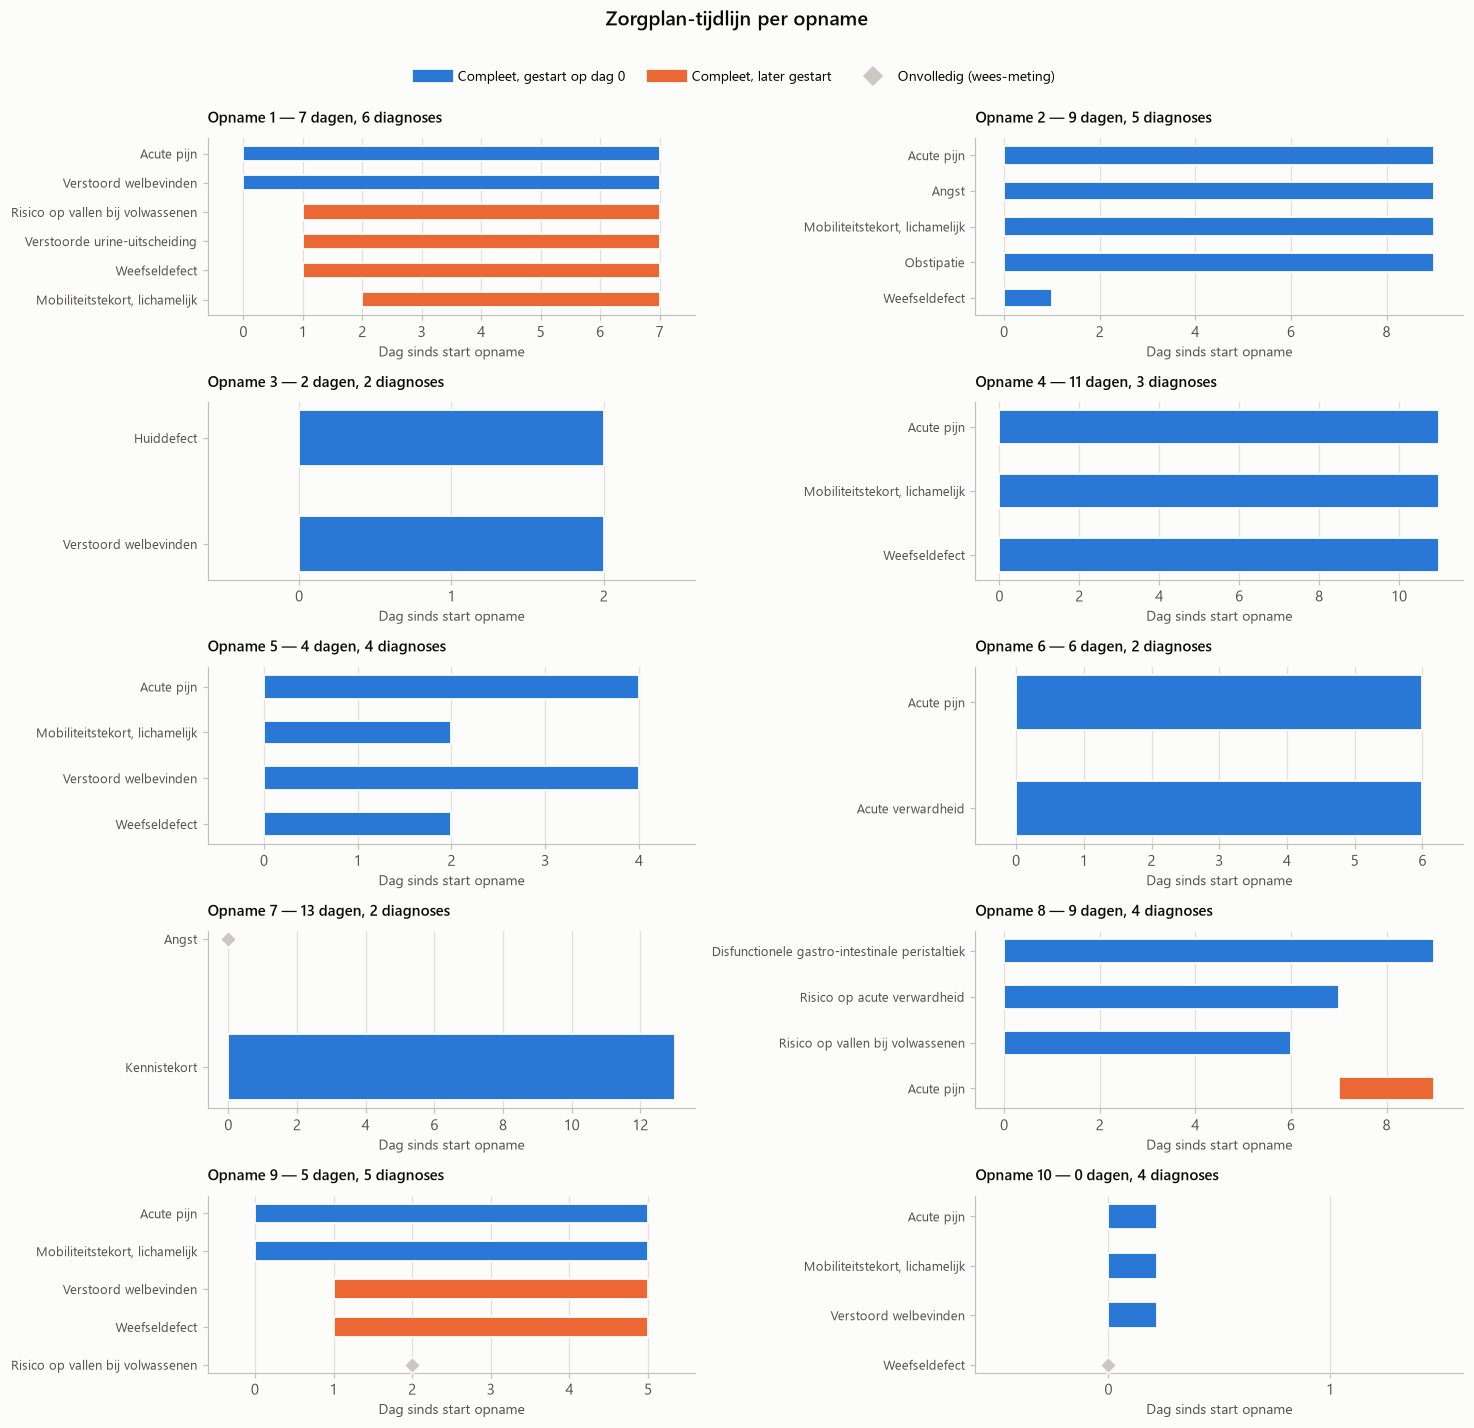

In [13]:
tijdlijn = df_diagnoses.copy()
tijdlijn["start_offset"] = (tijdlijn["Diagnose_startdatum"] - tijdlijn["Opname_startdatum"]).dt.days
tijdlijn["eind_offset"] = (tijdlijn["Diagnose_einddatum"] - tijdlijn["Opname_startdatum"]).dt.days

opnames = sorted(tijdlijn["Opnamenummer"].unique())
n_kol = 2
n_rij = int(np.ceil(len(opnames) / n_kol))
fig, assen = plt.subplots(n_rij, n_kol, figsize=(13.5, 2.1 * n_rij + 2))
assen = np.atleast_1d(assen).ravel()

MIN_BREEDTE = 0.22   # zodat een diagnose van 0 dagen zichtbaar blijft

for ax, opname in zip(assen, opnames):
    blok = tijdlijn[tijdlijn["Opnamenummer"] == opname].sort_values(
        ["start_offset", "Diagnose"], na_position="last"
    )
    los_dagen = int(blok["Opnameduur_dagen"].iloc[0])

    for y, (_, rij) in enumerate(blok.iterrows()):
        compleet_rij = rij["Compleetheid"] == "Compleet (Baseline + Eindscore)"
        if compleet_rij:
            start = float(rij["start_offset"])
            breedte = max(float(rij["eind_offset"]) - start, MIN_BREEDTE)
            kleur = BLAUW if rij["Gestart_op_dag0"] else ORANJE
            ax.barh(y, breedte, left=start, height=0.52, color=kleur,
                    edgecolor=SURFACE, linewidth=1.2, zorder=3)
        else:
            bekend = rij["start_offset"] if pd.notna(rij["start_offset"]) else rij["eind_offset"]
            ax.scatter([float(bekend)], [y], s=60, marker="D", color=NEUTRAAL,
                       edgecolor=SURFACE, linewidth=1.2, zorder=3)

    ax.set_yticks(range(len(blok)))
    ax.set_yticklabels(blok["Diagnose"].tolist(), fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlim(-0.6, max(los_dagen, 1) + 0.6)
    ax.set_title(f"Opname {int(opname)} — {los_dagen} dagen, {len(blok)} diagnoses", fontsize=10)
    ax.set_xlabel("Dag sinds start opname", fontsize=9)
    stijl_as(ax, "x")
    hele_dagen(ax, "x")

for ax in assen[len(opnames):]:
    ax.set_visible(False)

handvatten = [
    plt.Line2D([0], [0], color=BLAUW, linewidth=8, label="Compleet, gestart op dag 0"),
    plt.Line2D([0], [0], color=ORANJE, linewidth=8, label="Compleet, later gestart"),
    plt.Line2D([0], [0], marker="D", color=NEUTRAAL, linewidth=0, markersize=8,
               label="Onvolledig (wees-meting)"),
]
fig.legend(handles=handvatten, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Zorgplan-tijdlijn per opname", x=0.5, y=1.035, fontsize=13,
             fontweight="semibold", color=INK)
fig.tight_layout()
plt.show()

> **Conclusie pijler 2.** De opnameduur is de buitenste grens; de diagnoses daarbinnen lopen
> korter en starten niet allemaal op dag 0. Oranje balken zijn diagnoses die **tijdens** de
> opname zijn toegevoegd — precies de groep die in pijler 4 het leakage-risico veroorzaakt.

<a id="pijler3"></a>

---

## 3. Pijler 3 — Zorgplan-complexiteit versus opnameduur

De kernhypothese: **een complexer zorgplan hangt samen met een langere opname.** We meten
complexiteit op vier manieren:

| Kenmerk | Betekenis |
|---|---|
| `n_diagnoses_totaal` | alle unieke NANDA-diagnoses in de hele opname |
| `n_diagnoses_dag0` | alleen de diagnoses die op dag 0 al liepen |
| `n_diagnoses_actief_baseline` | diagnoses met minstens één Baseline-indicator `< 5` (echte klacht) |
| `n_indicatoren_totaal` | aantal unieke NOC-indicatoren in het zorgplan |

Omdat `Opnameduur_dagen` scheef verdeeld is en N klein is, kijken we naar **Spearman**
(rangcorrelatie, robuust) *en* **Pearson** (lineair) naast elkaar.

In [14]:
KENMERKEN = [
    "n_diagnoses_totaal",
    "n_diagnoses_dag0",
    "n_diagnoses_actief_baseline",
    "n_indicatoren_totaal",
]


def correlatietabel(tabel, kenmerken, doel="Opnameduur_dagen"):
    """Spearman en Pearson van elk kenmerk tegen het doel, met p-waarden."""
    rijen = []
    y = tabel[doel].to_numpy(dtype=float)
    for kenmerk in kenmerken:
        x = tabel[kenmerk].to_numpy(dtype=float)
        rho, p_spearman = stats.spearmanr(x, y)
        r, p_pearson = stats.pearsonr(x, y)
        rijen.append({
            "Kenmerk": kenmerk,
            "Spearman_rho": round(float(rho), 3),
            "Spearman_p": round(float(p_spearman), 3),
            "Pearson_r": round(float(r), 3),
            "Pearson_p": round(float(p_pearson), 3),
        })
    return pd.DataFrame(rijen)


correlaties = correlatietabel(df_opnames, KENMERKEN)
print(f"N = {len(df_opnames)} opnames. Bij deze steekproefgrootte zijn p-waarden indicatief,")
print("geen bewijs. Lees de richting en de orde van grootte, niet de significantie.")
correlaties

N = 10 opnames. Bij deze steekproefgrootte zijn p-waarden indicatief,
geen bewijs. Lees de richting en de orde van grootte, niet de significantie.


,Kenmerk,Spearman_rho,Spearman_p,Pearson_r,Pearson_p
0,n_diagnoses_totaal,-0.072,0.844,-0.101,0.781
1,n_diagnoses_dag0,0.039,0.914,0.059,0.872
2,n_diagnoses_actief_baseline,-0.068,0.851,-0.093,0.798
3,n_indicatoren_totaal,-0.040,0.912,0.054,0.883


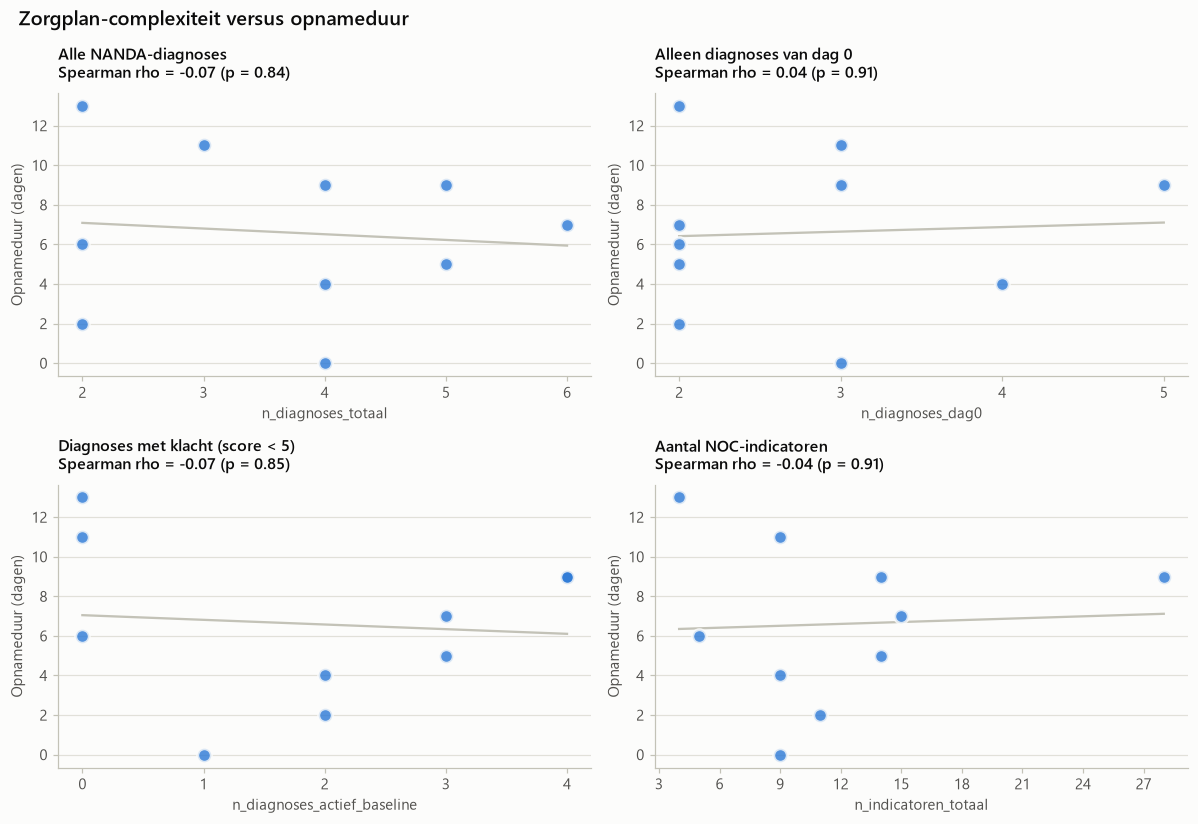

In [15]:
TITELS = {
    "n_diagnoses_totaal": "Alle NANDA-diagnoses",
    "n_diagnoses_dag0": "Alleen diagnoses van dag 0",
    "n_diagnoses_actief_baseline": "Diagnoses met klacht (score < 5)",
    "n_indicatoren_totaal": "Aantal NOC-indicatoren",
}

fig, assen = plt.subplots(2, 2, figsize=(11, 7.6))
for ax, kenmerk in zip(assen.ravel(), KENMERKEN):
    x = df_opnames[kenmerk].to_numpy(dtype=float)
    y = df_opnames["Opnameduur_dagen"].to_numpy(dtype=float)
    rij = correlaties.loc[correlaties["Kenmerk"] == kenmerk].iloc[0]

    ax.scatter(x, y, s=80, color=BLAUW, alpha=0.8, edgecolor=SURFACE, linewidth=2, zorder=3)
    if len(np.unique(x)) > 1:
        helling, snijpunt = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(xs, helling * xs + snijpunt, color=AS, linewidth=1.5, zorder=2)

    ax.set_title(f"{TITELS[kenmerk]}\nSpearman rho = {rij['Spearman_rho']:.2f} "
                 f"(p = {rij['Spearman_p']:.2f})", fontsize=10.5)
    ax.set_xlabel(kenmerk)
    ax.set_ylabel("Opnameduur (dagen)")
    stijl_as(ax, "y")
    hele_dagen(ax, "x")
    hele_dagen(ax, "y")

fig.suptitle("Zorgplan-complexiteit versus opnameduur", x=0.02, ha="left",
             fontsize=13, fontweight="semibold", color=INK)
fig.tight_layout()
plt.show()

In [16]:
# Hetzelfde verhaal als tabel, zodat de getallen ook zonder grafiek leesbaar zijn.
df_opnames[["Opnamenummer", "Opnameduur_dagen", *KENMERKEN,
            "baseline_score_gemiddeld", "pct_baseline_score_5"]].round(1)

,Opnamenummer,Opnameduur_dagen,n_diagnoses_totaal,n_diagnoses_dag0,n_diagnoses_actief_baseline,n_indicatoren_totaal,baseline_score_gemiddeld,pct_baseline_score_5
0,1,7,6,2,3,15,4.5,66.7
1,2,9,5,5,4,14,4.1,50.0
2,3,2,2,2,2,11,4.5,45.5
3,4,11,3,3,0,9,5.0,100.0
4,5,4,4,4,2,9,4.6,66.7
5,6,6,2,2,0,5,5.0,100.0
6,7,13,2,2,0,4,5.0,100.0
7,8,9,4,3,4,28,4.5,60.7
8,9,5,5,2,3,14,3.7,33.3
9,10,0,4,3,1,9,4.8,80.0


> **Conclusie pijler 3.** In deze testset is er **geen meetbare samenhang**: alle vier de
> correlaties liggen dicht bij nul, met p-waarden ver boven 0,05. Lees dat niet als "zorgplannen
> zeggen niets over opnameduur" — met 10 opnames kun je een effect van deze orde simpelweg niet
> aantonen. Wat deze sectie wél oplevert, is de **werkwijze**: dezelfde cel draait straks op
> 25.000 opnames en geeft dan een antwoord dat telt.
>
> Let bij die herhaling vooral op het **verschil** tussen `n_diagnoses_totaal` en
> `n_diagnoses_dag0`. Is de samenhang bij "alle diagnoses" duidelijk sterker dan bij "alleen
> dag 0", dan meet je voor een deel *omgekeerde causaliteit*: wie langer ligt, krijgt er
> diagnoses bij. Dat is het onderwerp van pijler 4.

<a id="pijler4"></a>

---

## 4. Pijler 4 — Startmoment van diagnoses & data leakage

Wil je de opnameduur **voorspellen op het moment van opname**, dan mag je alleen informatie
gebruiken die op dag 0 al bestond. `Start_dag_offset` zegt hoeveel dagen na de start van de
opname een diagnose zijn eerste Baseline kreeg.

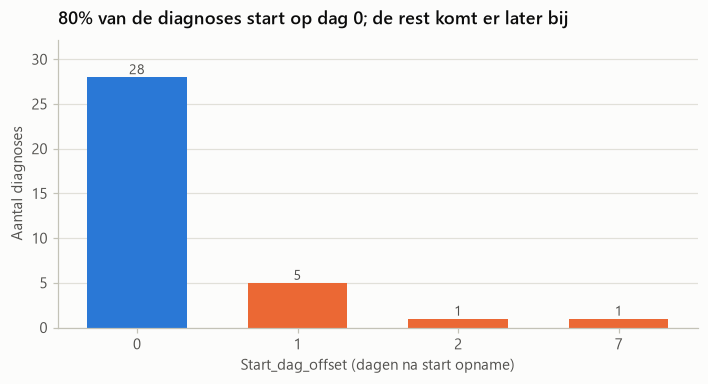

In [17]:
offsets = df_diagnoses["Start_dag_offset"].dropna().astype(int)
verdeling = offsets.value_counts().sort_index()
pct_dag0 = (offsets == 0).mean() * 100

fig, ax = plt.subplots(figsize=(7.5, 3.4))
kleuren = [BLAUW if dag == 0 else ORANJE for dag in verdeling.index]
balken = ax.bar(verdeling.index.astype(str), verdeling.to_numpy(), color=kleuren, width=0.62)
label_balken(ax, balken, verdeling.to_numpy())

ax.set_title(f"{pct_dag0:.0f}% van de diagnoses start op dag 0; de rest komt er later bij")
ax.set_xlabel("Start_dag_offset (dagen na start opname)")
ax.set_ylabel("Aantal diagnoses")
ax.set_ylim(0, verdeling.max() * 1.15)
stijl_as(ax, "y")
plt.show()

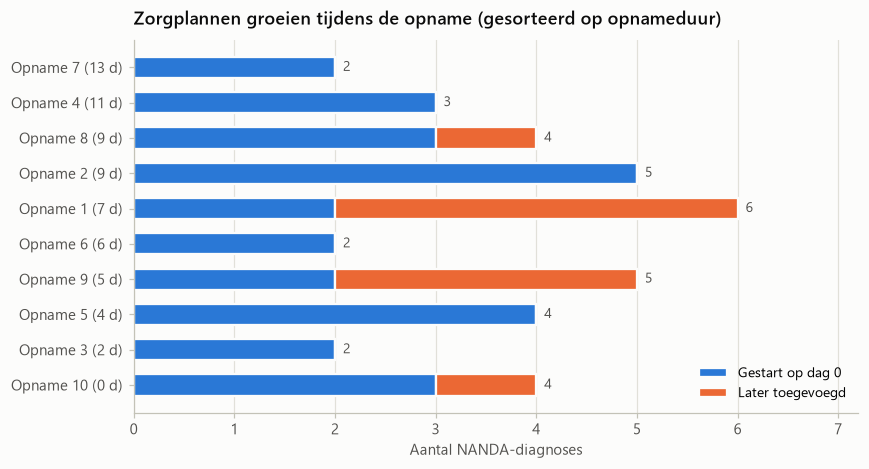

In [18]:
gesorteerd = df_opnames.sort_values("Opnameduur_dagen", ascending=False)
labels = [f"Opname {int(n)} ({int(d)} d)"
          for n, d in zip(gesorteerd["Opnamenummer"], gesorteerd["Opnameduur_dagen"])]
dag0 = gesorteerd["n_diagnoses_dag0"].to_numpy()
later = (gesorteerd["n_diagnoses_totaal"] - gesorteerd["n_diagnoses_dag0"]).to_numpy()

fig, ax = plt.subplots(figsize=(8.5, 4.4))
b1 = ax.barh(labels, dag0, color=BLAUW, height=0.6,
             edgecolor=SURFACE, linewidth=1.5, label="Gestart op dag 0")
b2 = ax.barh(labels, later, left=dag0, color=ORANJE, height=0.6,
             edgecolor=SURFACE, linewidth=1.5, label="Later toegevoegd")
label_balken(ax, b2, gesorteerd["n_diagnoses_totaal"].to_numpy(), horizontaal=True)

ax.invert_yaxis()
ax.set_title("Zorgplannen groeien tijdens de opname (gesorteerd op opnameduur)")
ax.set_xlabel("Aantal NANDA-diagnoses")
ax.set_xlim(0, gesorteerd["n_diagnoses_totaal"].max() * 1.2)
ax.legend(loc="lower right")
stijl_as(ax, "x")
hele_dagen(ax, "x")
plt.show()

In [19]:
# Hoeveel 'verdient' het model aan informatie die op dag 0 nog niet bestond?
rij_totaal = correlaties.loc[correlaties["Kenmerk"] == "n_diagnoses_totaal"].iloc[0]
rij_dag0 = correlaties.loc[correlaties["Kenmerk"] == "n_diagnoses_dag0"].iloc[0]

print("Samenhang met opnameduur (Spearman rho):")
print(f"  alle diagnoses : {rij_totaal['Spearman_rho']:+.2f}")
print(f"  alleen dag-0   : {rij_dag0['Spearman_rho']:+.2f}")
print(f"  verschil       : {rij_totaal['Spearman_rho'] - rij_dag0['Spearman_rho']:+.2f}")
print()
print("Op de volledige dataset is dit verschil de maat voor hoeveel een model 'verdient'")
print("aan informatie die bij opname nog niet bestond. Bij N = 10 is het ruis.")
print()
n_later = int((df_diagnoses["Start_dag_offset"] > 0).sum())
n_bekend = int(df_diagnoses["Start_dag_offset"].notna().sum())
n_opnames_gegroeid = int((df_opnames["n_diagnoses_later_gestart"] > 0).sum())
print(f"Diagnoses die pas na dag 0 starten : {n_later} van de {n_bekend} met bekende startdag")
print(f"Opnames waarvan het zorgplan groeide: {n_opnames_gegroeid} van de {len(df_opnames)}")

Samenhang met opnameduur (Spearman rho):
  alle diagnoses : -0.07
  alleen dag-0   : +0.04
  verschil       : -0.11

Op de volledige dataset is dit verschil de maat voor hoeveel een model 'verdient'
aan informatie die bij opname nog niet bestond. Bij N = 10 is het ruis.

Diagnoses die pas na dag 0 starten : 7 van de 35 met bekende startdag
Opnames waarvan het zorgplan groeide: 3 van de 10


> **Conclusie pijler 4.** Een deel van de zorgplannen groeit tijdens de opname. Gebruik je
> `n_diagnoses_totaal` als feature in een model dat bij opname voorspelt, dan lekt
> toekomstinformatie het model in en lijkt het model beter dan het is. **Bouw het basismodel
> op dag-0-features** (`n_diagnoses_dag0`, `n_diagnoses_actief_baseline`) en gebruik de
> totalen hooguit als bovengrens-referentie.

<a id="pijler5"></a>

---

## 5. Pijler 5 — ICD-10 (medisch) versus NANDA/NOC (verpleegkundig)

De vraag achter het hele project: **voegt het verpleegkundige zorgplan iets toe bovenop de
medische diagnose?** Als twee patiënten dezelfde ICD-10-code hebben maar sterk verschillende
opnameduur, dan moet die verschil ergens anders vandaan komen — mogelijk uit het zorgplan.

In [20]:
per_icd = (
    df_opnames.groupby(["ICD10Code", "ICD10Omschrijving"])
    .agg(Aantal_opnames=("Opnamenummer", "size"),
         LOS_mediaan=("Opnameduur_dagen", "median"),
         LOS_min=("Opnameduur_dagen", "min"),
         LOS_max=("Opnameduur_dagen", "max"),
         Diagnoses_gemiddeld=("n_diagnoses_totaal", "mean"),
         Indicatoren_gemiddeld=("n_indicatoren_totaal", "mean"))
    .round(1)
    .sort_values("Aantal_opnames", ascending=False)
)
per_icd

,,Aantal_opnames,LOS_mediaan,LOS_min,LOS_max,Diagnoses_gemiddeld,Indicatoren_gemiddeld
ICD10Code,ICD10Omschrijving,,,,,,
S72.00,Fractuur van femurhals; gesloten,3,7.0,6,13,3.3,8.0
K59.0,Constipatie,1,9.0,9,9,4.0,28.0
S01.0,Open wond van behaarde hoofd,1,2.0,2,2,2.0,11.0
M00.97,"Pyogene artritis, niet gespecificeerd, van enkel en voet",1,11.0,11,11,3.0,9.0
S32.40,Fractuur van acetabulum; gesloten,1,9.0,9,9,5.0,14.0
S72.10,Pertrochantaire fractuur; gesloten,1,5.0,5,5,5.0,14.0
S82.80,Fracturen van overige gespecificeerde delen van onderbeen; gesloten,1,4.0,4,4,4.0,9.0
S92.50,Fractuur van overige teen; gesloten,1,0.0,0,0,4.0,9.0


Focusgroep: S72.00 - Fractuur van femurhals; gesloten (3 opnames)


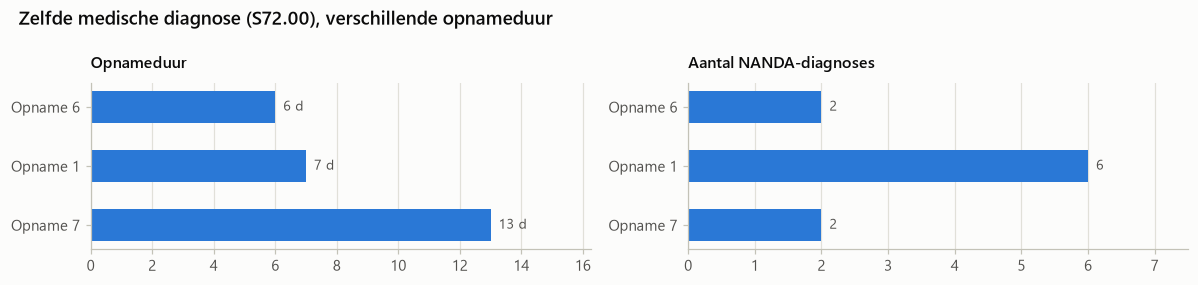

In [21]:
# De enige ICD-10-groep met meer dan een opname is geschikt voor een eerlijke vergelijking.
groepen = df_opnames["ICD10Code"].value_counts()
focus_code = groepen.index[0]
focus = df_opnames[df_opnames["ICD10Code"] == focus_code].sort_values("Opnameduur_dagen")
omschrijving = focus["ICD10Omschrijving"].iloc[0]

print(f"Focusgroep: {focus_code} - {omschrijving} ({len(focus)} opnames)")

labels = [f"Opname {int(n)}" for n in focus["Opnamenummer"]]
fig, assen = plt.subplots(1, 2, figsize=(11, 2.6))

for ax, (kolom, titel, eenheid) in zip(assen, [
    ("Opnameduur_dagen", "Opnameduur", " d"),
    ("n_diagnoses_totaal", "Aantal NANDA-diagnoses", ""),
]):
    waarden = focus[kolom].to_numpy()
    balken = ax.barh(labels, waarden, color=BLAUW, height=0.55)
    label_balken(ax, balken, waarden, horizontaal=True, suffix=eenheid)
    ax.set_title(titel, fontsize=10.5)
    ax.set_xlim(0, max(waarden.max(), 1) * 1.25)
    ax.invert_yaxis()
    stijl_as(ax, "x")

fig.suptitle(f"Zelfde medische diagnose ({focus_code}), verschillende opnameduur",
             x=0.02, ha="left", fontsize=12.5, fontweight="semibold", color=INK)
fig.tight_layout()
plt.show()

In [22]:
# Welke verpleegkundige diagnoses zitten er in de zorgplannen van die groep?
focus_diagnoses = df_diagnoses[df_diagnoses["ICD10Code"] == focus_code]
kruistabel = (
    pd.crosstab(focus_diagnoses["Diagnose"], focus_diagnoses["Opnamenummer"])
    .rename(columns=lambda n: f"Opname {int(n)}")
)
kruistabel.loc["— opnameduur (dagen) —"] = [
    int(df_opnames.loc[df_opnames["Opnamenummer"] == int(kol.split()[-1]), "Opnameduur_dagen"].iloc[0])
    for kol in kruistabel.columns
]
kruistabel

Opnamenummer,Opname 1,Opname 6,Opname 7
Diagnose,,,
Acute pijn,1,1,0
Acute verwardheid,0,1,0
Angst,0,0,1
Kennistekort,0,0,1
"Mobiliteitstekort, lichamelijk",1,0,0
Risico op vallen bij volwassenen,1,0,0
Verstoord welbevinden,1,0,0
Verstoorde urine-uitscheiding,1,0,0
Weefseldefect,1,0,0


> **Conclusie pijler 5.** Binnen dezelfde ICD-10-code loopt de opnameduur uiteen, terwijl de
> zorgplannen qua samenstelling verschillen. Dat is precies de ruimte waarin NANDA/NOC
> voorspellende waarde kán hebben bovenop de medische code. Met 10 opnames is dit een
> *illustratie van de methode*; op de volledige dataset wordt dit de centrale toets
> (bijvoorbeeld: model met alleen ICD-10 versus model met ICD-10 + zorgplankenmerken).

<a id="aanbevelingen"></a>

---

## 6. Aanbevelingen voor feature engineering & modellering

**Doelvariabele**

- Gebruik `Opnameduur_dagen` uit `df_opnames`. Onthoud dat dit een **ondergrens** is
  (eerste tot laatste meting, niet opname tot ontslag). Vraag bij HMC na of de echte
  opname- en ontslagdatum meegeleverd kan worden — dat is de grootste kwaliteitswinst. Antwoord: Ja het is de echte opname en ontslag datum. De ontslag datum kan ook betekenen dat de patient naar een ander afdeling verplaatst wordt. 
- Overweeg `log1p(Opnameduur_dagen)` of een duurmodel: LOS is rechtsscheef.
- Behandel dagopnames (`Is_dagopname`) apart, of als eigen klasse.

**Features die op dag 0 bekend zijn (veilig)**

- `n_diagnoses_dag0`, `n_diagnoses_actief_baseline`
- `baseline_score_gemiddeld`, `baseline_score_min`, `aantal_indicatoren_score_onder_5`
- De ICD-10-code (of het hoofdstuk/de eerste drie tekens als die te fijnmazig is)
- Eventueel: welke NANDA-diagnoses op dag 0 aanwezig zijn, als dummy-kolommen

**Features die je bewust NIET als dag-0-feature gebruikt (leakage)**

- `n_diagnoses_totaal`, `n_diagnoses_later_gestart`, `n_indicatoren_totaal`
- Alles uit de `Eindscore`: `Gezondheidswinst`, `Eind_mean_score`, `Diagnoseduur_dagen`

**Datakwaliteit vooraf**

- Sluit onvolledige diagnoses expliciet uit bij duuranalyses; zet ze niet op 0.
- Score `5` betekent "geen probleem". Een telling van *alle* indicatoren meet daardoor
  vooral registratie-ijver; een telling van indicatoren met score `< 5` meet zorgzwaarte.

**Validatie**

- Met ~25.000 opnames: splits op **patiëntniveau**, niet op rijniveau, zodat dezelfde
  patiënt niet in train én test zit.
- Vergelijk expliciet drie modellen: (1) alleen ICD-10, (2) alleen NANDA/NOC dag 0,
  (3) beide. Het verschil tussen (1) en (3) is het antwoord op de onderzoeksvraag.

**Volgende notebook**

Maak `notebooks/02_feature_engineering.ipynb` en begin met:

```python
from src.data_loader import load_and_clean_hmc_data, build_diagnosis_table, build_admission_table
```

zodat je dezelfde definities hergebruikt als hier.